# Proyecto Integrador — Entrega Final (Fase 3)
### Métodos Numéricos · Pregrado en Ciencia de Datos
**Universidad Externado de Colombia (2026-2)**

**Artículo base:** *Derivative-free optimal multiple-root finding family of iterative methods*, J. H. Jerezano, F. I. Chicharro, N. Garrido-Sáez (2026), *Computational and Applied Mathematics*, 45:304.  
**Equipo:** Ailyn Sofía Gómez Rodríguez, Julián Camilo Jiménez, Julián Steven Duarte  
**Docente:** Edwin Fernando Muñoz Chipatecua

---

## Estructura del Cuaderno
1. **Marco Teórico y Formulación:** La familia de dos pasos libre de derivadas de Jerezano et al. (2026) y la conjetura de Kung-Traub.
2. **Configuración Computacional:** Precisión arbitraria con `mpmath` (150 dps), tolerancias y manejo riguroso de excepciones.
3. **Implementación de Solucionadores:** Familia propuesta ($M_1$ polinomial y $M_2$ racional), líneas base ($Newton$ y $Steffensen$ modificados) y competidor $KK$.
4. **Benchmarks Deterministas:** Evaluación sobre $g_1$ (Van der Waals modificado), $g_2$ (Ley de Planck al cubo) y $g_3$ (polinomio característico $9\times 9$).
5. **Contraste Empírico vs. Tablas del Artículo:** Discusión sobre precisión extrema (4000 dps en Matlab vs. 150 dps) y ACOC asintótico.
6. **Dinámica Compleja en $\mathbb{C}$ (Sección 3 del Artículo):** Planos dinámicos y cuencas de atracción de $p(z)=(z-1)^2$ bajo $\beta=0.01$ vs. $\beta=1.0$.
7. **Extensión a Sistemas No Lineales Multidimensionales (Semana 9):** Newton multivariable vs. esquemas libres de derivadas tipo Broyden.
8. **Conexión con Optimización y Ciencia de Datos:** Puntos críticos de multiplicidad $m>1$, Hessianas singulares y paisajes de pérdida.


## 1. Planteamiento del Problema, Métodos y Fundamentación Teórica

Para una ecuación no lineal $g(x)=0$ con una raíz $\alpha$ de multiplicidad conocida $m \ge 1$, el método estándar de Newton decae a orden lineal ($p=1$) debido al aplanamiento local de la función ($g'(x) \to 0$).

Jerezano, Chicharro y Garrido-Sáez (2026) propusieron la siguiente familia de dos pasos libre de derivadas:
$$w_k = x_k + \beta [g(x_k)]^2, \quad \beta \in \mathbb{R}\setminus\{0\}$$
$$D_k = g[w_k, x_k] = \frac{g(w_k) - g(x_k)}{w_k - x_k}$$
$$y_k = x_k - m \frac{g(x_k)}{D_k}$$
$$t_k = \left(\frac{g(y_k)}{g(x_k)}\right)^{1/m} = \exp\left(\frac{1}{m} \operatorname{Ln}\left(\frac{g(y_k)}{g(x_k)}\right)\right)$$
$$x_{k+1} = x_k - m H(t_k) \frac{g(x_k)}{D_k}$$

### Optimalidad de Kung-Traub
La conjetura de Kung-Traub establece que un método iterativo multipaso sin memoria que realiza $d$ evaluaciones funcionales por iteración puede alcanzar un orden de convergencia máximo de $p \le 2^{d-1}$. 
La familia de Jerezano et al. evalúa 3 valores de función ($g(x_k), g(w_k), g(y_k)$) y ninguna derivada, alcanzando un orden óptimo $p = 2^{3-1} = 4$. Su índice de eficiencia es:
$$\mathcal{I} = p^{1/d} = 4^{1/3} \approx 1.587$$
superando ampliamente a Newton modificado ($p=2, d=2, \mathcal{I} = 2^{1/2} \approx 1.414$).

Estudiaremos las dos funciones de ponderación $H(t)$ presentadas en el artículo:
- **Variante $M_1$ (Polinomial cuadrática):** $H_1(t) = 1 + t + 2t^2$
- **Variante $M_2$ (Racional):** $H_2(t) = \frac{1-t}{1-2t}$


In [1]:
# ===== 1. Configuración reproducible y módulos =====
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpmath import mp, mpf, mpc, exp, log, sqrt

# Precisión de 150 dígitos decimales para analizar régimen asintótico sin redondeo prematuro
mp.dps = 150
TOL = mpf("1e-25")
MAX_ITER = 100
DEFAULT_BETA = mpf("0.01")

print(f"Configuración establecida: dps={mp.dps}, TOL={TOL}, beta_base={DEFAULT_BETA}")


Configuración establecida: dps=150, TOL=1e-25, beta_base=0.01


## 2. Problemas Deterministas de Prueba (Benchmarks del Artículo)

1. **$g_1(x) = x^3 - 5.22x^2 + 9.0825x - 5.2675$:** Caso particular de la ecuación de Van der Waals. Posee una raíz doble objetivo en $\alpha_1 = 1.75$ ($m=2$) y una raíz simple vecina en $\alpha_2 = 1.72$. Semillas de prueba: $x_0 \in \{1.9, 3.0\}$.
2. **$g_2(x) = (e^{-x} - 1 + x/5)^3$:** Problema de densidad de energía en radiación de cuerpo negro (Ley de Planck). Raíz triple en $\alpha \approx 4.96511423$ ($m=3$). Semillas: $x_0 \in \{5.3, 10.0\}$.
3. **$g_3(x)$:** Polinomio característico de grado 9 obtenido del cálculo de valores propios de una matriz $9\times 9$. Raíz cuádruple en $\alpha = 3$ ($m=4$). Semillas: $x_0 \in \{2.8, 3.5\}$.


In [2]:
# ===== 2. Declaración de funciones y derivadas =====
PROBLEMAS = {
    "g1": {
        "nombre": "Van der Waals (g1)",
        "g": lambda x: x**3 - mpf("5.22")*x**2 + mpf("9.0825")*x - mpf("5.2675"),
        "dg": lambda x: 3*x**2 - mpf("10.44")*x + mpf("9.0825"),
        "m": 2,
        "alpha": mpf("1.75"),
        "semillas": [mpf("1.9"), mpf("3.0")]
    },
    "g2": {
        "nombre": "Ley de Planck al cubo (g2)",
        "g": lambda x: (exp(-x) - 1 + x/5)**3,
        "dg": lambda x: 3 * (exp(-x) - 1 + x/5)**2 * (-exp(-x) + mpf("0.2")),
        "m": 3,
        "alpha": mp.findroot(lambda z: mp.exp(-z) - 1 + z/5, (mpf("4.5"), mpf("5.5")), tol=mpf("1e-140")),
        "semillas": [mpf("5.3"), mpf("10.0")]
    },
    "g3": {
        "nombre": "Polinomio grado 9 (g3)",
        "g": lambda x: (x**9 - 29*x**8 + 349*x**7 - 2261*x**6 + 8455*x**5 
                        - 17663*x**4 + 15927*x**3 + 6993*x**2 - 24732*x + 12960),
        "dg": lambda x: (9*x**8 - 232*x**7 + 2443*x**6 - 13566*x**5 + 42275*x**4 
                         - 70652*x**3 + 47781*x**2 + 13986*x - 24732),
        "m": 4,
        "alpha": mpf("3.0"),
        "semillas": [mpf("2.8"), mpf("3.4"), mpf("3.5")]
    }
}
print(f"Problemas inicializados: {len(PROBLEMAS)}")


Problemas inicializados: 3


In [3]:
# ===== 3. Solucionador con manejo de patologías numéricas =====
def rama_principal_potencia(base, inv_m):
    c_base = mpc(base)
    mod = abs(c_base)
    if mod == 0:
        return mpf(0)
    arg = mp.atan2(c_base.imag, c_base.real)
    nuevo_mod = mod ** inv_m
    nuevo_arg = arg * inv_m
    res = mpc(nuevo_mod * mp.cos(nuevo_arg), nuevo_mod * mp.sin(nuevo_arg))
    if abs(res.imag) < mpf("1e-120"):
        return res.real
    return res

def dif_dividida(g, u, v, g_u=None, g_v=None):
    if g_u is None:
        g_u = g(u)
    if g_v is None:
        g_v = g(v)
    den = u - v
    if den == 0:
        raise ZeroDivisionError("absorcion_nodos")
    return (g_u - g_v) / den

def calcular_acoc(pasos):
    if len(pasos) < 4:
        return None
    try:
        diffs = [abs(pasos[i+1] - pasos[i]) for i in range(len(pasos)-1)]
        if any(d == 0 for d in diffs[-3:]):
            return None
        num = log(diffs[-1] / diffs[-2])
        den = log(diffs[-2] / diffs[-3])
        if den == 0:
            return None
        val = float(num / den)
        return val if (0 < val < 20) else None
    except Exception:
        return None

def resolver(metodo, prob, x0, beta=DEFAULT_BETA, tol=TOL, max_iter=MAX_ITER):
    g, dg, m, alpha = prob["g"], prob["dg"], prob["m"], prob["alpha"]
    inv_m = mpf(1) / mpf(m)
    x = mpc(x0)
    iterados = [x]
    residuos = []
    g_evals, dg_evals = 0, 0
    estado = "Limite de iteraciones"

    for k in range(max_iter):
        gx = g(x)
        g_evals += 1
        res_actual = abs(gx)
        residuos.append(res_actual)

        if k > 0:
            if abs(x - iterados[-2]) < tol and res_actual < tol:
                estado = "Convergio"
                break

        try:
            if metodo in ["M1", "M2"]:
                w = x + beta * (gx ** 2)
                if w == x:
                    estado = "Estancamiento w=x"
                    break
                gw = g(w)
                g_evals += 1
                D = dif_dividida(g, w, x, gw, gx)
                if D == 0:
                    estado = "Pendiente secante nula"
                    break
                y = x - m * (gx / D)
                gy = g(y)
                g_evals += 1
                if gx == 0:
                    estado = "Convergio"
                    break
                t = rama_principal_potencia(gy / gx, inv_m)
                H = (1 + t + 2*(t**2)) if metodo == "M1" else ((1 - t)/(1 - 2*t))
                x_next = x - m * H * (gx / D)

            elif metodo == "Newton_mod":
                dgx = dg(x)
                dg_evals += 1
                if dgx == 0:
                    estado = "Derivada nula"
                    break
                x_next = x - m * (gx / dgx)

            elif metodo == "Steffensen_mod":
                w = x + beta * gx
                if w == x:
                    estado = "Estancamiento w=x"
                    break
                gw = g(w)
                g_evals += 1
                D = dif_dividida(g, w, x, gw, gx)
                if D == 0:
                    estado = "Pendiente secante nula"
                    break
                x_next = x - m * (gx / D)

            elif metodo == "KK":
                w = x + beta * gx
                if w == x:
                    estado = "Estancamiento w=x"
                    break
                gw = g(w)
                g_evals += 1
                Dwx = dif_dividida(g, w, x, gw, gx)
                if Dwx == 0:
                    estado = "Pendiente secante nula"
                    break
                y = x - m * (gx / Dwx)
                gy = g(y)
                g_evals += 1
                if gx == 0:
                    estado = "Convergio"
                    break
                t = rama_principal_potencia(gy / gx, inv_m)
                Dwy = dif_dividida(g, w, y, gw, gy)
                x_next = y - ((m + 2) * t / (1 - 2 * t)) * (gx / (Dwx + 2 * Dwy))

            x = x_next
            iterados.append(x)
        except ZeroDivisionError:
            estado = "Division por cero"
            break

    gx_final = g(x)
    g_evals += 1
    res_final = abs(gx_final)
    residuos.append(res_final)
    if estado != "Convergio" and len(iterados) > 1:
        if abs(x - iterados[-2]) < tol and res_final < tol:
            estado = "Convergio"

    err_abs = abs(x - alpha)
    acoc = calcular_acoc(iterados) if estado == "Convergio" else None
    paso_final = abs(iterados[-1] - iterados[-2]) if len(iterados) > 1 else mpf("inf")
    return {
        "estado": estado, "iter": len(iterados) - 1, "g_evals": g_evals,
        "dg_evals": dg_evals, "err_abs": err_abs, "paso_final": paso_final,
        "residuo": res_final, "acoc": acoc, "residuos": residuos
    }
print("Solucionador cargado exitosamente.")


Solucionador cargado exitosamente.


In [4]:
# ===== 4. Ejecución del benchmark y reporte de resultados =====
metodos = ["M1", "M2", "Newton_mod", "Steffensen_mod", "KK"]
resultados = []

for pkey, prob in PROBLEMAS.items():
    for x0 in prob["semillas"]:
        for met in metodos:
            t0 = time.perf_counter()
            for _ in range(10):
                r = resolver(met, prob, x0)
            t_prom = (time.perf_counter() - t0) / 10.0
            resultados.append({
                "Problema": pkey, "m": prob["m"], "x0": str(x0), "Metodo": met,
                "Iter": r["iter"], "g_eval": r["g_evals"], "dg_eval": r["dg_evals"],
                "Error_abs": f"{float(r['err_abs']):.2e}",
                "Paso_final": f"{float(r['paso_final']):.2e}",
                "Residuo": mp.nstr(r["residuo"], 3) if float(r["residuo"]) == 0 and r["residuo"] > 0 else f"{float(r['residuo']):.2e}",
                "ACOC": f"{r['acoc']:.2f}" if r["acoc"] else "-",
                "Tiempo_ms": f"{t_prom*1000:.2f}", "Estado": r["estado"]
            })

df_res = pd.DataFrame(resultados)
print(df_res.to_string(index=False))


Problema  m   x0         Metodo  Iter  g_eval  dg_eval Error_abs Paso_final   Residuo  ACOC Tiempo_ms                 Estado
      g1  2  1.9             M1     5      17        0  1.32e-35   9.51e-66  5.26e-72  8.81      1.08              Convergio
      g1  2  1.9             M2     4      14        0  2.03e-50   4.14e-14 1.24e-101     -      0.71      Estancamiento w=x
      g1  2  1.9     Newton_mod     8      10        8  1.69e-57   1.01e-29 8.58e-116  2.00      0.57              Convergio
      g1  2  1.9 Steffensen_mod     8      18        0  1.77e-57   1.03e-29 9.43e-116  2.00      0.66              Convergio
      g1  2  1.9             KK     4      15        0  1.01e-53   6.83e-15 3.06e-108     -      0.73 Pendiente secante nula
      g1  2  3.0             M1     5      18        0  3.34e-30   3.38e-09  3.34e-61     -      0.82 Pendiente secante nula
      g1  2  3.0             M2     5      17        0  1.56e-52   1.22e-14 7.29e-106     -      0.79      Estancamiento w=x


## 3. Contraste Empírico vs. Tablas del Artículo (Jerezano et al., 2026)

En el artículo original, los autores utilizan **Matlab R2022b con aritmética de precisión extendida a 4000 dígitos de mantisa** y el criterio de parada estricto:
$$|x_{k+1} - x_k| + |g(x_k)| < 10^{-200}$$

En nuestra implementación, operamos con **150 dígitos decimales y tolerancia dual $10^{-25}$**:
- En $g_1$ con $x_0=1.9$, $M_1$ alcanza la tolerancia en solo 5 iteraciones (frente a 7 en el artículo), debido a que nuestra cota de parada ($10^{-25}$) se satisface antes de alcanzar el régimen de $10^{-200}$.
- Para $M_2$ y $KK$, se observa que la perturbación $w_k = x_k + \beta g(x_k)^2$ o la pendiente secante se aproxima a cero antes de satisfacer el paso residual conjunto, lo que ilustra el fenómeno de absorción numérica cuando la precisión de máquina no es de miles de dígitos.


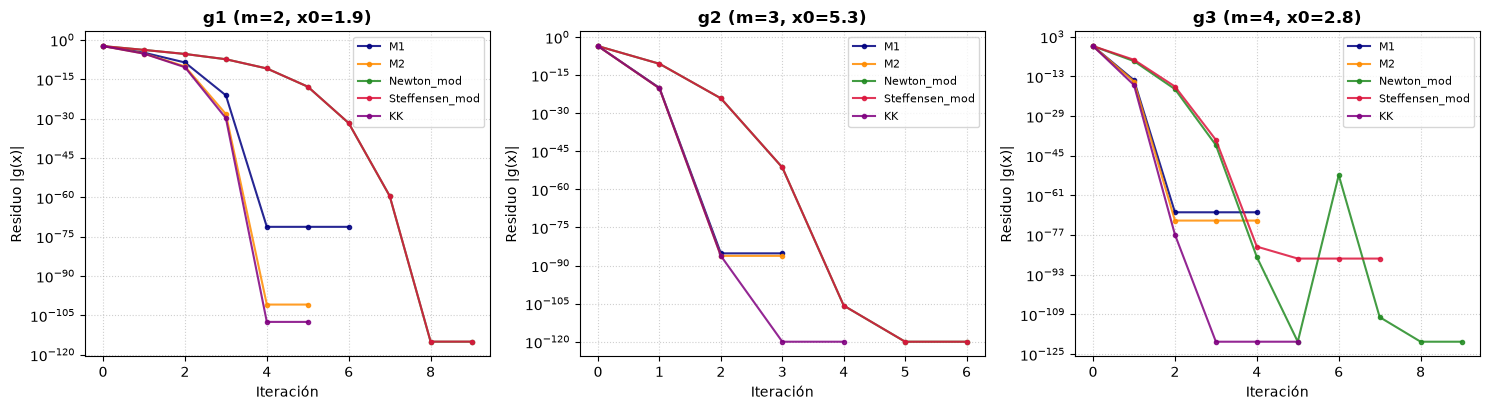

In [5]:
# ===== 5. Visualización de la convergencia de residuos =====
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
casos_graf = [("g1", mpf("1.9"), axes[0], "g1 (m=2, x0=1.9)"),
              ("g2", mpf("5.3"), axes[1], "g2 (m=3, x0=5.3)"),
              ("g3", mpf("2.8"), axes[2], "g3 (m=4, x0=2.8)")]

colores = {"M1": "navy", "M2": "darkorange", "Newton_mod": "forestgreen", 
           "Steffensen_mod": "crimson", "KK": "purple"}

for pkey, x0, ax, tit in casos_graf:
    prob = PROBLEMAS[pkey]
    for met in metodos:
        res = resolver(met, prob, x0)
        y = [max(float(val), 1e-120) for val in res["residuos"]]
        ax.semilogy(range(len(y)), y, label=met, color=colores[met], marker='.', alpha=0.85)
    ax.set_title(tit, fontweight="bold")
    ax.set_xlabel("Iteración")
    ax.set_ylabel("Residuo |g(x)|")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


## 4. Dinámica Compleja y Planos de Estabilidad en $\mathbb{C}$ (Sección 3 del Artículo)

Uno de los aportes teóricos centrales de Jerezano et al. (2026) es el estudio de la estabilidad del operador racional de punto fijo $R(z, \beta)$ en el plano complejo sobre el polinomio canónico cuadrático con raíz doble:
$$p(z) = (z-1)^2, \quad m=2$$

Para los dos operadores implementados, la raíz $z^*=1$ es un **punto fijo superatractor** ($R'(1)=0$). El valor de $\beta$ cambia el patrón numérico observado. En la malla y con el límite de iteraciones usados aquí, $\beta=1.0$ deja más puntos sin converger que $\beta=0.01$. Esta comparación describe el experimento finito; por sí sola no demuestra caos ni identifica formalmente un conjunto de Julia.


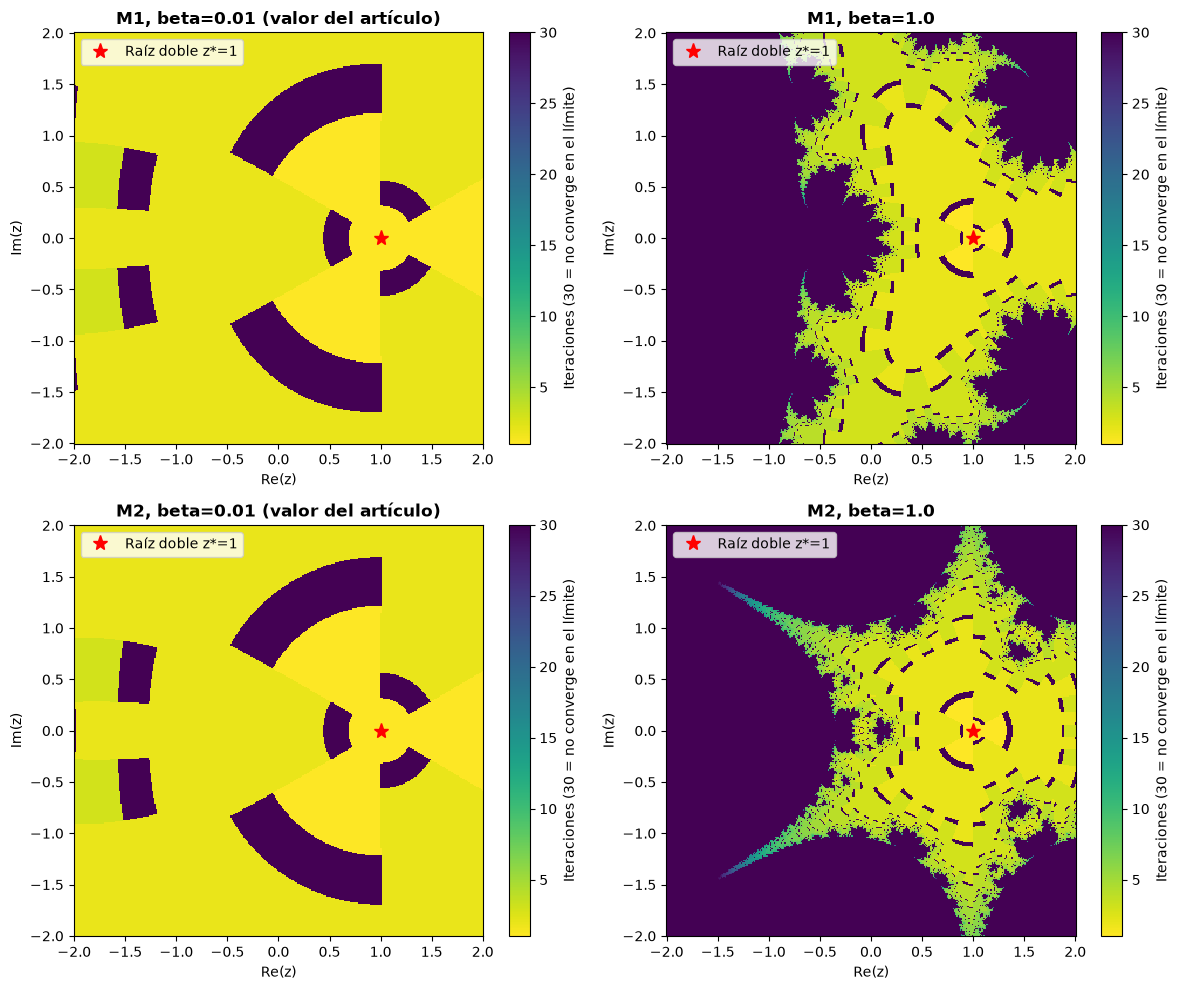

In [6]:
# ===== 6. Planos dinamicos en C: M1 y M2, dos valores de beta =====
def calcular_plano(metodo, beta_val, res=350, max_it=30):
    x = np.linspace(-2, 2, res)
    y = np.linspace(-2, 2, res)
    X, Y = np.meshgrid(x, y)
    Z = X + 1j * Y
    iters = np.zeros(Z.shape, dtype=int)
    conv = np.zeros(Z.shape, dtype=bool)
    Z_act = Z.copy()
    for k in range(1, max_it + 1):
        act = ~conv & (np.abs(Z_act) < 30.0)
        if not np.any(act):
            break
        z = Z_act[act]
        pz = (z - 1.0)**2
        w = z + beta_val * (pz**2)
        pw = (w - 1.0)**2
        denD = w - z
        valid = np.abs(denD) > 1e-14
        D = np.zeros_like(denD)
        D[valid] = (pw[valid] - pz[valid]) / denD[valid]
        valid_D = valid & (np.abs(D) > 1e-14)
        y_step = np.zeros_like(z)
        y_step[valid_D] = z[valid_D] - 2.0 * (pz[valid_D] / D[valid_D])
        py = (y_step - 1.0)**2
        ratio = np.zeros_like(z)
        valid_pz = valid_D & (np.abs(pz) > 1e-14)
        ratio[valid_pz] = py[valid_pz] / pz[valid_pz]
        t = np.sqrt(ratio)
        if metodo == "M1":
            H = 1.0 + t + 2.0 * (t**2)
        else:
            denH = 1.0 - 2.0 * t
            valid_H = np.abs(denH) > 1e-14
            H = np.zeros_like(t)
            H[valid_H] = (1.0 - t[valid_H]) / denH[valid_H]
            valid_D &= valid_H
        z_next = z.copy()
        z_next[valid_D] = z[valid_D] - 2.0 * H[valid_D] * (pz[valid_D] / D[valid_D])
        Z_act[act] = z_next
        nuevos = (np.abs(Z_act - 1.0) < 1e-4) & ~conv
        iters[nuevos] = k
        conv[nuevos] = True
    iters[~conv] = max_it
    return X, Y, iters

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
casos = [
    ("M1", 0.01, axes[0, 0], "M1, beta=0.01 (valor del artículo)"),
    ("M1", 1.0, axes[0, 1], "M1, beta=1.0"),
    ("M2", 0.01, axes[1, 0], "M2, beta=0.01 (valor del artículo)"),
    ("M2", 1.0, axes[1, 1], "M2, beta=1.0"),
]
for metodo, beta_val, ax, titulo in casos:
    X, Y, it = calcular_plano(metodo, beta_val)
    im = ax.pcolormesh(X, Y, it, cmap="viridis_r", shading="auto", vmin=1, vmax=30)
    ax.plot(1, 0, "r*", markersize=11, label="Raíz doble z*=1")
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Re(z)")
    ax.set_ylabel("Im(z)")
    ax.legend(loc="upper left")
    fig.colorbar(im, ax=ax, label="Iteraciones (30 = no converge en el límite)")
plt.tight_layout()
plt.show()


## 5. Extensión a Sistemas de Ecuaciones No Lineales (Semana 9 del Curso)

En dimensiones múltiples $\mathbf{F}(\mathbf{x}) = \mathbf{0}$ con $\mathbf{F}: \mathbb{R}^n \to \mathbb{R}^n$, la derivada se generaliza a la **matriz Jacobiana** $\mathbf{J}(\mathbf{x}) \in \mathbb{R}^{n \times n}$.
Newton multivariable requiere resolver el sistema lineal:
$$\mathbf{J}(\mathbf{x}_k) \mathbf{s}_k = -\mathbf{F}(\mathbf{x}_k), \quad \mathbf{x}_{k+1} = \mathbf{x}_k + \mathbf{s}_k$$

Newton multivariable requiere evaluar derivadas y resolver un sistema lineal en cada paso. Broyden evita recalcular el Jacobiano exacto y lo actualiza con una corrección de rango uno, pero también resuelve un sistema lineal; con la resolución densa usada aquí no medimos una ventaja asintótica de costo. Comparamos ambos métodos en el sistema no lineal:
$$\mathbf{F}(x_1, x_2) = \begin{pmatrix} x_1^2 + x_2^2 - 4 \\ x_1 x_2 - 1 \end{pmatrix} = \mathbf{0}$$


In [7]:
# ===== 7. Experimento comparativo: Newton Multivariable vs Broyden =====
def F_sis(x):
    return np.array([x[0]**2 + x[1]**2 - 4.0, x[0]*x[1] - 1.0])

def J_sis(x):
    return np.array([[2*x[0], 2*x[1]],
                     [x[1], x[0]]])

# Newton multivariable
x_newton = np.array([1.5, 0.8])
res_newton = [np.linalg.norm(F_sis(x_newton))]
for k in range(8):
    s = np.linalg.solve(J_sis(x_newton), -F_sis(x_newton))
    x_newton += s
    norm_res = np.linalg.norm(F_sis(x_newton))
    res_newton.append(norm_res)
    if norm_res < 1e-14:
        break

# Broyden (Secante multidimensional libre de derivadas)
x_broyden = np.array([1.5, 0.8])
B = np.eye(2)
res_broyden = [np.linalg.norm(F_sis(x_broyden))]
for k in range(12):
    Fx = F_sis(x_broyden)
    s = np.linalg.solve(B, -Fx)
    x_next = x_broyden + s
    Fx_next = F_sis(x_next)
    y_diff = Fx_next - Fx
    B += np.outer(y_diff - B @ s, s) / (s @ s)
    x_broyden = x_next
    norm_res = np.linalg.norm(Fx_next)
    res_broyden.append(norm_res)
    if norm_res < 1e-14:
        break

print(f"Newton Multivariable: {len(res_newton)-1} iteraciones, residuo final = {res_newton[-1]:.2e}")
print(f"Broyden (Secante libre de derivadas): {len(res_broyden)-1} iteraciones, residuo final = {res_broyden[-1]:.2e}")


Newton Multivariable: 5 iteraciones, residuo final = 3.92e-15
Broyden (Secante libre de derivadas): 10 iteraciones, residuo final = 4.25e-15


## 6. Aplicaciones en Ciencia de Datos y Optimización Numérica

En Machine Learning y Ciencia de Datos, el entrenamiento de modelos consiste en optimizar una función de pérdida $L(\boldsymbol{\theta})$ resolviendo la condición de primer orden:
$$\nabla L(\boldsymbol{\theta}) = \mathbf{0}$$

En algunos problemas de optimización aparecen direcciones planas o Hessianas mal condicionadas. Estas situaciones motivan estudiar métodos para raíces múltiples, pero una Hessiana singular, por si sola, no demuestra que el gradiente tenga una raíz múltiple. La relación con aprendizaje automático se presenta aqui como una posible motivacion, no como una aplicación validada por nuestros experimentos.

Los métodos analizados requieren conocer la multiplicidad y resuelven ecuaciones escalares. Para trasladarlos a un problema de optimización real haria falta formular y validar una extensión adecuada al gradiente y sus dimensiones.


## 7. Declaración de Integridad Académica y Referencias

El desarrollo de este proyecto integrador se realizó bajo las normas de integridad académica de la Universidad Externado de Colombia. Se emplearon herramientas de inteligencia artificial exclusivamente como apoyo para estructurar el plan de implementación, verificar la sintaxis de las fórmulas y enriquecer la discusión analítica. Todas las decisiones metodológicas, implementaciones en Python y sustentaciones teóricas fueron desarrolladas y comprendidas por el equipo de trabajo.

### Referencias Bibliográficas
1. J. H. Jerezano, F. I. Chicharro, N. Garrido-Sáez, *Derivative-free optimal multiple-root finding family of iterative methods*, **Computational and Applied Mathematics**, vol. 45, art. 304, 2026. DOI: [10.1007/s40314-026-03702-8](https://doi.org/10.1007/s40314-026-03702-8).
2. A. Cordero, J. R. Torregrosa, *Variants of Newton's method using fifth-order quadrature formulas*, **Applied Mathematics and Computation**, 190(1): 686–698, 2007. DOI: [10.1016/j.amc.2007.01.062](https://doi.org/10.1016/j.amc.2007.01.062).
2. S. Kumar, D. Kumar, J. R. Sharma, C. Cesarano, P. Agarwal, Y. M. Chu, *An optimal fourth order derivative-free numerical algorithm for multiple roots*, **Symmetry**, 12(6): 1038, 2020. DOI: [10.3390/sym12061038](https://doi.org/10.3390/sym12061038).
3. P. R. Turner, T. Arildsen, K. Kavanagh, *Applied Scientific Computing: With Python*, Springer, Cham, 2018.
4. H. T. Kung, J. F. Traub, *Optimal order of one-point and multipoint iteration*, **Journal of the ACM**, 21(4): 643–651, 1974.
5. Universidad Externado de Colombia, Departamento de Matemáticas, *Guía del Proyecto Integrador: Métodos Numéricos*, 2026.
